# Problema 2 – Regressão Logística para Previsão de Doenças Cardíacas

PAM0466 – Sistemas Inteligentes

Doenças cardiovasculares são a principal causa de morte no mundo, responsáveis por cerca de 18 milhões de óbitos por ano segundo a OMS. O diagnóstico precoce é determinante para o sucesso do tratamento. Existe, portanto, uma necessidade real de ferramentas capazes de estimar o risco de um paciente com base em dados clínicos simples, coletados em consulta de rotina. É nesse contexto que o aprendizado de máquina pode contribuir. Um modelo de classificação treinado com dados históricos de pacientes diagnosticados é capaz de aprender quais combinações de variáveis clínicas estão associadas à presença de doença cardíaca e aplicar esse aprendizado a novos pacientes.

Neste projeto, você é convidado a construir um modelo utilizando regressão logística para prever a presença de doença cardíaca com base em um conjunto de dados clínicos.

O projeto utiliza o dataset Heart Disease Cleveland (UCI Machine Learning Repository – disponível em https://archive.ics.uci.edu/dataset/45/heart+disease), com registros de 303 pacientes e 13 variáveis clínicas. Os diagnósticos foram confirmados por cateterismo cardíaco, o que garante rótulos confiáveis. As variáveis incluem:

- age — idade do paciente em anos;
- sex — sexo biológico (1 = masculino, 0 = feminino);
- cp — tipo de dor no peito: angina típica (1), atípica (2), não anginosa (3) ou assintomático (4);
- trestbps — pressão arterial em repouso em mmHg;
- chol — colesterol sérico total em mg/dl;
- fbs — glicemia em jejum acima de 120 mg/dl (1 = sim, 0 = não);
- restecg — resultado do ECG em repouso: normal (0), alteração na onda ST-T (1) ou hipertrofia ventricular (2);
- thalach — frequência cardíaca máxima atingida no teste de esforço;
- exang — angina induzida por exercício (1 = sim, 0 = não);
- oldpeak — depressão do segmento ST durante o esforço, indicador de isquemia;
- slope — inclinação do segmento ST no pico do esforço: ascendente (1), plano (2) ou descendente (3);
- ca — número de artérias coronárias com obstrução visível na fluoroscopia (0 a 3);
- thal — cintilografia de tálio: normal (3), defeito fixo / infarto prévio (6) ou defeito reversível / isquemia ativa (7);

A saída é a variável target, que indica o diagnóstico original de 0 a 4, binarizado para 0 (sem doença) e 1 (com doença) antes do treinamento.

Realize as seguintes tarefas utilizando o dataset fornecido:

1. Treinar um modelo de LogisticRegression do scikit-learn utilizando os dados de treino, com os seguintes parâmetros: solver='liblinear', random_state=42 e max_iter=1000. Indique quantas iterações foram necessárias para a convergência do modelo.
2. Avaliar o modelo utilizando os dados de teste e calcular as seguintes métricas: Acurácia, Precisão, Recall, F1-score e Curva ROC com valor de AUC.

Realize o pré-processamento dos dados, incluindo a normalização ou padronização das variáveis independentes, tratamento de valores ausentes, divisão dos dados em conjuntos de treino e teste e binarização das variáveis alvo.

## Pré-processamento dos dados

> Realize o pré-processamento dos dados, incluindo a normalização ou padronização das variáveis independentes, tratamento de valores ausentes, divisão dos dados em conjuntos de treino e teste e binarização das variáveis alvo.

Etapas do pré-processamento, na ordem em que são feitas abaixo: (1) carregar os dados e dar nome à variável alvo (`target`); (2) tratar valores ausentes; (3) binarizar a variável alvo; (4) dividir em treino e teste; (5) padronizar as variáveis independentes. A divisão vem antes do preenchimento dos ausentes e da padronização para que mediana, média e desvio padrão sejam calculados só no treino, sem vazamento de informação do teste.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# o arquivo não tem cabeçalho: damos os nomes das 13 variáveis do enunciado + a variável alvo (target)
colunas = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
           'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

# na_values='?' faz o pandas ler o símbolo '?' (usado no arquivo para dado ausente) como NaN
df = pd.read_csv('processed.cleveland_questao2.data', header=None, names=colunas, na_values='?')

print('Formato (pacientes, colunas):', df.shape)
df.head()

Formato (pacientes, colunas): (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### Valores ausentes

In [2]:
# quantidade de valores ausentes (NaN) em cada coluna
print(df.isnull().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


Só `ca` (4 ausentes) e `thal` (2 ausentes) têm valores faltando. Eles serão preenchidos pela **mediana** de cada coluna, calculada **só no treino** (logo depois da divisão). A mediana é o valor central dos dados válidos e, em `ca` e `thal`, que são variáveis discretas, ela é um valor possível da própria variável.

### Binarização da variável alvo

In [3]:
# target original: 0 = sem doença; 1, 2, 3, 4 = graus de doença
print('Distribuição original do target:')
print(df['target'].value_counts().sort_index())

# binarização: qualquer valor > 0 vira 1 (com doença); 0 continua 0 (sem doença)
df['target'] = (df['target'] > 0).astype(int)

print()
print('Distribuição após a binarização:')
print(df['target'].value_counts().sort_index())

Distribuição original do target:
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Distribuição após a binarização:
target
0    164
1    139
Name: count, dtype: int64


### Divisão treino/teste

In [4]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['target'])    # 13 variáveis independentes
y = df['target']                   # variável alvo binária

# 80% treino / 20% teste; stratify=y mantém a mesma proporção de doentes nos dois conjuntos;
# random_state=42 fixa o sorteio (resultado reproduzível)
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print('Tamanho do treino:', len(x_train))
print('Tamanho do teste :', len(x_test))
print(f'Proporção de doentes no treino: {y_train.mean():.3f} | no teste: {y_test.mean():.3f}')

Tamanho do treino: 242
Tamanho do teste : 61
Proporção de doentes no treino: 0.459 | no teste: 0.459


### Preenchimento dos ausentes pela mediana (calculada no treino)

In [5]:
# mediana de 'ca' e 'thal' calculada SÓ no treino
medianas = x_train[['ca', 'thal']].median()
print('Medianas do treino:')
print(medianas)

# a mesma mediana do treino preenche os ausentes dos dois conjuntos
x_train = x_train.fillna(medianas)
x_test = x_test.fillna(medianas)

print()
print('Ausentes restantes no treino:', int(x_train.isnull().sum().sum()))
print('Ausentes restantes no teste :', int(x_test.isnull().sum().sum()))

Medianas do treino:
ca      0.0
thal    3.0
dtype: float64

Ausentes restantes no treino: 0
Ausentes restantes no teste : 0


### Padronização das variáveis independentes

Z-score: $z = \dfrac{x - \mu}{\sigma}$ (média 0 e desvio padrão 1). Padronizamos só as variáveis contínuas (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`); as binárias e categóricas (`sex`, `cp`, `fbs`, ...) ficam como estão. A média e o desvio são aprendidos no treino (`fit`) e apenas aplicados no teste (`transform`).

In [6]:
from sklearn.preprocessing import StandardScaler

colunas_continuas = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

# cópias, para não alterar os DataFrames anteriores
x_train = x_train.copy()
x_test = x_test.copy()

scaler = StandardScaler()
x_train[colunas_continuas] = scaler.fit_transform(x_train[colunas_continuas])   # aprende μ e σ no treino e aplica
x_test[colunas_continuas] = scaler.transform(x_test[colunas_continuas])         # só aplica, com μ e σ do treino

# verificação: média ≈ 0 e desvio = 1 nas colunas padronizadas do treino
print('Média :', x_train[colunas_continuas].mean().round(4).to_dict())
print('Desvio:', x_train[colunas_continuas].std(ddof=0).round(4).to_dict())

Média : {'age': -0.0, 'trestbps': -0.0, 'chol': 0.0, 'thalach': -0.0, 'oldpeak': 0.0}
Desvio: {'age': 1.0, 'trestbps': 1.0, 'chol': 1.0, 'thalach': 1.0, 'oldpeak': 1.0}


## Tarefa 1 - Treinar um modelo de LogisticRegression do scikit-learn utilizando os dados de treino, com os seguintes parâmetros: solver='liblinear', random_state=42 e max_iter=1000. Indique quantas iterações foram necessárias para a convergência do modelo.

A regressão logística calcula uma combinação linear das variáveis e a transforma em probabilidade pela função sigmoide:

$$ z = \theta_0 + \theta_1 x_1 + ... + \theta_p x_p \qquad P(y = 1 \mid x) = \sigma(z) = \frac{1}{1 + e^{-z}} $$

Se $P \geq 0{,}5$ o modelo prevê **com doença** (1); caso contrário, **sem doença** (0). Os coeficientes são ajustados por um algoritmo iterativo; o atributo `n_iter_` do scikit-learn informa quantas iterações foram usadas até a convergência.

In [7]:
from sklearn.linear_model import LogisticRegression

# modelo com os parâmetros pedidos no enunciado
modelo = LogisticRegression(
    solver='liblinear',   # algoritmo de otimização
    random_state=42,      # semente (reprodutibilidade)
    max_iter=1000         # limite máximo de iterações
)

# treinamento com os dados de treino
modelo.fit(x_train, y_train)

# n_iter_ guarda o número de iterações realizadas até a convergência
print('Iterações até a convergência (n_iter_):', int(modelo.n_iter_[0]))
print('Limite permitido (max_iter)           :', modelo.max_iter)

Iterações até a convergência (n_iter_): 5
Limite permitido (max_iter)           : 1000


In [8]:
# coeficientes aprendidos (theta) e razão de chances (e^theta) de cada variável
print('Intercepto (theta0):', round(modelo.intercept_[0], 4))
coef = pd.DataFrame({'theta': modelo.coef_[0], 'razão de chances': np.exp(modelo.coef_[0])}, index=x_train.columns)
print(coef.sort_values('theta', key=abs, ascending=False).round(4))

Intercepto (theta0): -3.2881
           theta  razão de chances
ca        0.9957            2.7067
sex       0.8015            2.2288
exang     0.7985            2.2223
thalach  -0.5284            0.5896
oldpeak   0.4028            1.4960
fbs      -0.3968            0.6725
thal      0.2879            1.3336
trestbps  0.2226            1.2493
cp        0.2024            1.2243
restecg   0.1712            1.1867
chol      0.1459            1.1571
slope    -0.1400            0.8694
age      -0.1093            0.8965


**Resposta.** O modelo foi treinado com `solver='liblinear'`, `random_state=42` e `max_iter=1000`. O atributo `n_iter_` mostra que foram necessárias **5 iterações** até a convergência, muito abaixo do limite de 1000, portanto o algoritmo convergiu sem problemas.

Sobre os coeficientes: uma razão de chances maior que 1 aumenta a chance de doença; menor que 1 diminui. As variáveis de maior efeito são `ca` (mais artérias obstruídas, mais risco), `sex` (masculino) e `exang` (angina no exercício) com efeito positivo, e `thalach` (frequência cardíaca máxima alta) com efeito protetor.

## Tarefa 2 - Avaliar o modelo utilizando os dados de teste e calcular as seguintes métricas: Acurácia, Precisão, Recall, F1-score e Curva ROC com valor de AUC.

Todas as métricas partem da matriz de confusão (positivo = com doença):

- **VP** (verdadeiro positivo): era doente e o modelo previu doente;
- **VN** (verdadeiro negativo): era saudável e o modelo previu saudável;
- **FP** (falso positivo): era saudável, mas o modelo previu doente (alarme falso);
- **FN** (falso negativo): era doente, mas o modelo previu saudável (omissão).

$$ Acurácia = \frac{VP + VN}{VP + VN + FP + FN} \quad Precisão = \frac{VP}{VP + FP} \quad Recall = \frac{VP}{VP + FN} \quad F1 = 2\,\frac{Precisão \cdot Recall}{Precisão + Recall} $$

- **Precisão:** de todos que o modelo classificou como doentes, quantos eram doentes (penaliza falsos positivos);
- **Recall:** de todos os doentes, quantos o modelo detectou (penaliza falsos negativos);
- **F1:** média harmônica entre precisão e recall.

                 previsto sem doença  previsto com doença
real sem doença                   27                    6
real com doença                    2                   26
VN = 27 | FP = 6 | FN = 2 | VP = 26


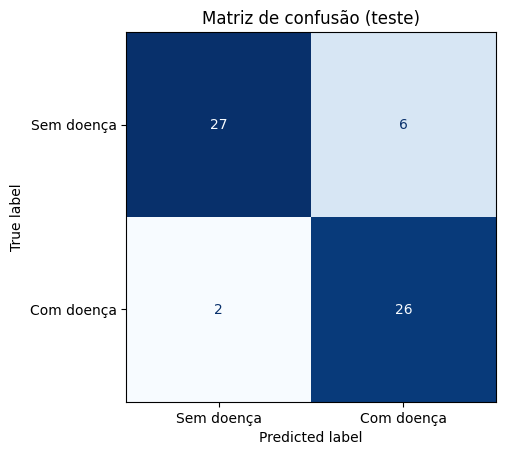

In [9]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# previsão da classe (0 ou 1) para os pacientes do teste
y_pred = modelo.predict(x_test)

# matriz de confusão: linhas = real, colunas = previsto
cm = confusion_matrix(y_test, y_pred)
vn, fp, fn, vp = cm.ravel()
print(pd.DataFrame(cm, index=['real sem doença', 'real com doença'], columns=['previsto sem doença', 'previsto com doença']))
print(f'VN = {vn} | FP = {fp} | FN = {fn} | VP = {vp}')

ConfusionMatrixDisplay(cm, display_labels=['Sem doença', 'Com doença']).plot(cmap='Blues', colorbar=False)
plt.grid(False)
plt.title('Matriz de confusão (teste)')
plt.show()

In [10]:
# métricas no conjunto de teste
acuracia = accuracy_score(y_test, y_pred)
precisao = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# o F1 também pode ser calculado direto pela fórmula, a partir de precisão e recall
f1_formula = 2 * precisao * recall / (precisao + recall)

print(f'Acurácia : {acuracia:.4f}')
print(f'Precisão : {precisao:.4f}')
print(f'Recall   : {recall:.4f}')
print(f'F1-score : {f1:.4f}  (pela fórmula: {f1_formula:.4f})')

Acurácia : 0.8689
Precisão : 0.8125
Recall   : 0.9286
F1-score : 0.8667  (pela fórmula: 0.8667)


### Curva ROC e AUC

A curva ROC avalia o classificador em **todos os limiares de decisão**: o eixo Y é a taxa de verdadeiros positivos (recall) e o eixo X é a taxa de falsos positivos, $TFP = \frac{FP}{FP + VN}$. Um classificador perfeito passa pelo canto superior esquerdo. O **AUC** (área sob a curva) resume a curva em um número entre 0,5 (equivale a sortear) e 1 (perfeito).

AUC: 0.9545
Quantidade de limiares avaliados na curva: 14


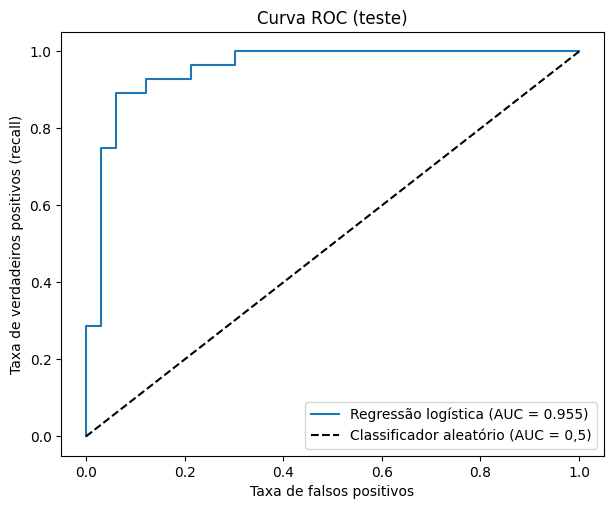

In [11]:
from sklearn.metrics import roc_auc_score, roc_curve

# probabilidade prevista de ter doença (segunda coluna do predict_proba)
y_prob = modelo.predict_proba(x_test)[:, 1]

# fpr = taxa de falsos positivos; tpr = taxa de verdadeiros positivos; thresholds = limiares testados
fpr, tpr, limiares = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
print(f'AUC: {auc:.4f}')
print('Quantidade de limiares avaliados na curva:', len(limiares))

plt.figure(figsize=(7, 5.5))
plt.plot(fpr, tpr, label=f'Regressão logística (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Classificador aleatório (AUC = 0,5)')
plt.xlabel('Taxa de falsos positivos')
plt.ylabel('Taxa de verdadeiros positivos (recall)')
plt.title('Curva ROC (teste)')
plt.legend()
plt.show()

In [12]:
# resumo final de todas as métricas, em uma tabela
resumo = pd.Series({'Acurácia': acuracia, 'Precisão': precisao, 'Recall': recall, 'F1-score': f1, 'AUC': auc}, name='Teste')
print(resumo.round(4))

Acurácia    0.8689
Precisão    0.8125
Recall      0.9286
F1-score    0.8667
AUC         0.9545
Name: Teste, dtype: float64


**Resposta.** Resultados no conjunto de teste (61 pacientes) estão na tabela impressa acima. O modelo acerta cerca de 87% dos casos. O **recall de 0,93** significa que, de 28 pacientes doentes, só 2 foram classificados como saudáveis, o que é desejável em diagnóstico, onde deixar passar um doente é o erro mais grave. A **precisão de 0,81** indica que, dos 32 pacientes apontados como doentes, 26 realmente eram (6 alarmes falsos). O **F1 de 0,87** equilibra as duas métricas. O **AUC de 0,955** está na faixa excelente (0,9 a 1,0): o modelo separa bem as duas classes em praticamente qualquer limiar de decisão.

Observação: o teste tem só 61 pacientes, então cada paciente muda a acurácia em ≈ 1,6 ponto percentual; o resultado deve ser lido com essa margem de incerteza.